In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Loading Data into a DataFrame(data)

data = pd.read_csv("/kaggle/input/europe-population-data/europe.csv")
data.head()

,Unnamed: 0,country_name,Continent,region,local_name,capital,area,population,population_per_sq_km,male_life_expectancy,female_life_expectancy,birth_rate,death_rate
0,0,Austria,Europe,Western Europe,Österreich,Vienna,"83,879 km²","8,917,000",106.3,78.9,83.6,9.4,10.3
1,1,Belgium,Europe,Western Europe,België / Belgique,Brussels,"30,530 km²","11,544,000",378.1,78.6,83.1,9.9,11.0
2,2,France,Europe,Western Europe,France,Paris,"549,087 km²","67,380,000",122.7,79.2,85.3,10.9,9.9
3,3,Germany,Europe,Western Europe,Deutschland,Berlin,"357,580 km²","83,161,000",232.6,78.6,83.4,9.3,11.9
4,4,Liechtenstein,Europe,Western Europe,Liechtenstein,Vaduz,161 km²,"38,137",237.6,80.1,83.6,9.1,8.2


In [3]:
#Getting Rows and Col

print("No.of Rows : ",data.shape[0],"No .of col : ",data.shape[1])

No.of Rows :  36 No .of col :  13


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              36 non-null     int64  
 1   country_name            36 non-null     object 
 2   Continent               36 non-null     object 
 3   region                  36 non-null     object 
 4   local_name              36 non-null     object 
 5   capital                 36 non-null     object 
 6   area                    36 non-null     object 
 7   population              36 non-null     object 
 8   population_per_sq_km    36 non-null     object 
 9   male_life_expectancy    36 non-null     float64
 10  female_life_expectancy  36 non-null     float64
 11  birth_rate              36 non-null     float64
 12  death_rate              36 non-null     float64
dtypes: float64(4), int64(1), object(8)
memory usage: 3.8+ KB


In [5]:
#Checking for NULL values 

data.isna().any()

Unnamed: 0                False
country_name              False
Continent                 False
region                    False
local_name                False
capital                   False
area                      False
population                False
population_per_sq_km      False
male_life_expectancy      False
female_life_expectancy    False
birth_rate                False
death_rate                False
dtype: bool

In [6]:
data.describe().style.highlight_max(color='lightgreen',axis=0)     #Stat for the dataset

,Unnamed: 0,male_life_expectancy,female_life_expectancy,birth_rate,death_rate
count,36.000000,36.000000,36.000000,36.000000,36.000000
mean,17.500000,75.944444,81.847222,9.619444,11.355556
std,10.535654,4.722496,2.884291,1.109908,2.968833
min,0.000000,66.400000,76.200000,7.100000,6.300000
25%,8.750000,72.075000,79.850000,8.975000,9.475000
50%,17.500000,78.300000,83.100000,9.650000,11.200000
75%,26.250000,79.625000,84.125000,10.225000,12.700000
max,35.000000,81.700000,85.300000,12.300000,18.000000


In [7]:
data.dtypes

Unnamed: 0                  int64
country_name               object
Continent                  object
region                     object
local_name                 object
capital                    object
area                       object
population                 object
population_per_sq_km       object
male_life_expectancy      float64
female_life_expectancy    float64
birth_rate                float64
death_rate                float64
dtype: object

In [8]:
#Datacleaning

data['population_per_sq_km2'] = data['population_per_sq_km'].str.replace(',','')

data['population_per_sq_km2'] = data['population_per_sq_km2'].astype(float)

data['population_per_sq_km2']

0      106.300
1      378.100
2      122.700
3      232.600
4      237.600
5      243.400
6      419.800
7      209.200
8       45.180
9       62.470
10     135.600
11     104.800
12      77.410
13     121.200
14      80.780
15       8.428
16     111.300
17      73.130
18     135.900
19      29.320
20      16.340
21       3.558
22      70.940
23      29.470
24      42.810
25      13.970
26      23.140
27     275.900
28      98.710
29      81.090
30    1610.000
31      44.990
32     111.700
33      78.080
34     101.700
35      93.620
Name: population_per_sq_km2, dtype: float64

In [9]:
#Datatypes

data.dtypes

Unnamed: 0                  int64
country_name               object
Continent                  object
region                     object
local_name                 object
capital                    object
area                       object
population                 object
population_per_sq_km       object
male_life_expectancy      float64
female_life_expectancy    float64
birth_rate                float64
death_rate                float64
population_per_sq_km2     float64
dtype: object

<AxesSubplot:xlabel='male_life_expectancy', ylabel='female_life_expectancy'>

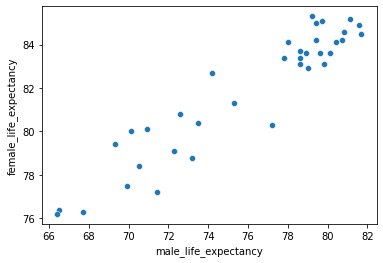

In [10]:
sns.scatterplot(x=data['male_life_expectancy'],y=data['female_life_expectancy'])

<AxesSubplot:xlabel='birth_rate', ylabel='death_rate'>

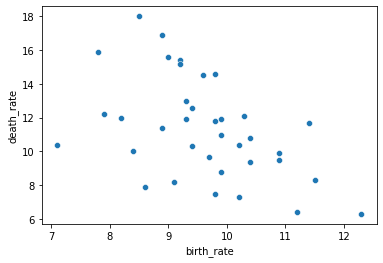

In [11]:
sns.scatterplot(x=data['birth_rate'],y=data['death_rate'])

In [12]:
data.drop('Unnamed: 0',axis=1,inplace=True)

<AxesSubplot:ylabel='region'>

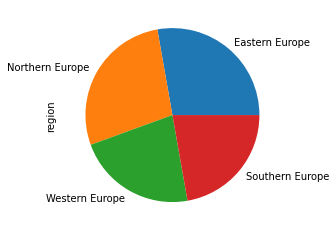

In [13]:
data['region'].value_counts().plot(kind='pie')

<AxesSubplot:>

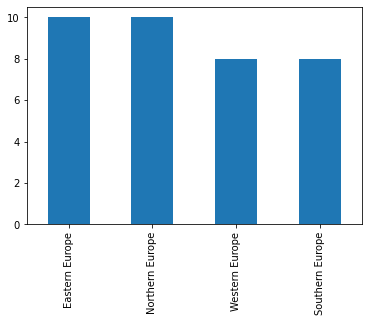

In [14]:
data['region'].value_counts().plot(kind='bar')

In [15]:
#Top 10 country with high male_life_expectancy

data.sort_values(by=['male_life_expectancy'],ascending=False).head(10)['country_name']

21          Iceland
25           Norway
7       Switzerland
30            Malta
26           Sweden
22          Ireland
4     Liechtenstein
6       Netherlands
35            Spain
18          Denmark
Name: country_name, dtype: object

In [16]:
#Top 10 country with high female_life_expectancy

data.sort_values(by=['female_life_expectancy'],ascending=False).head(10)['country_name']

2          France
7     Switzerland
35          Spain
20        Finland
25         Norway
30          Malta
21        Iceland
5      Luxembourg
26         Sweden
32       Portugal
Name: country_name, dtype: object

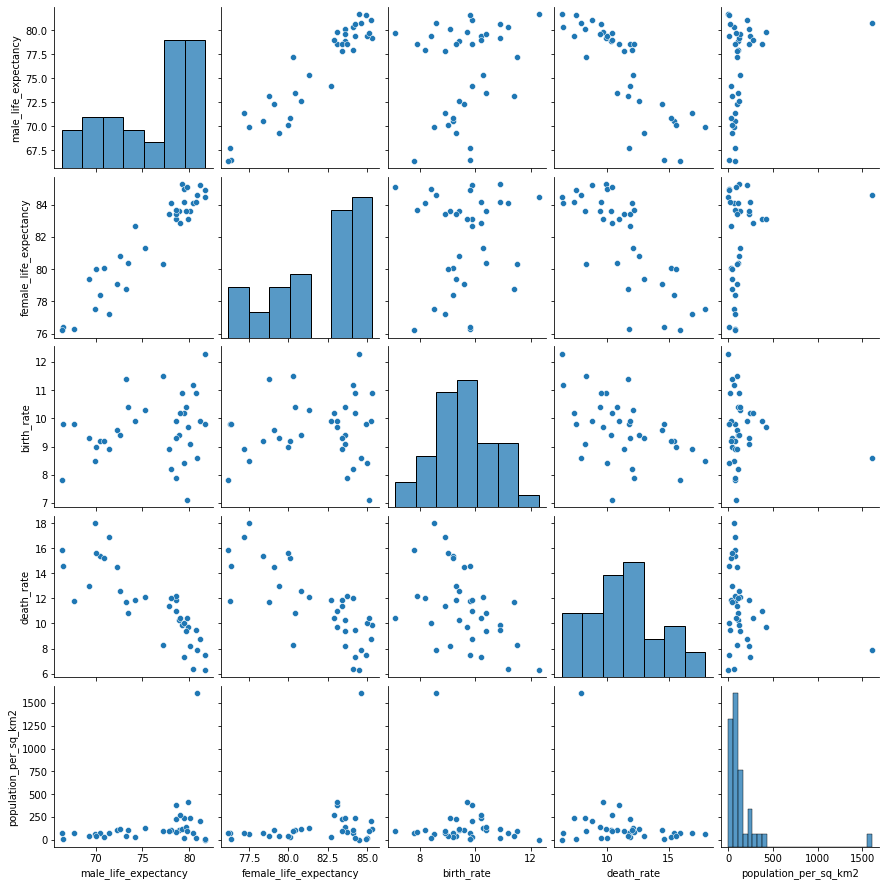

In [17]:
sns.pairplot(data)
plt.show()

<AxesSubplot:xlabel='country_name', ylabel='male_life_expectancy'>

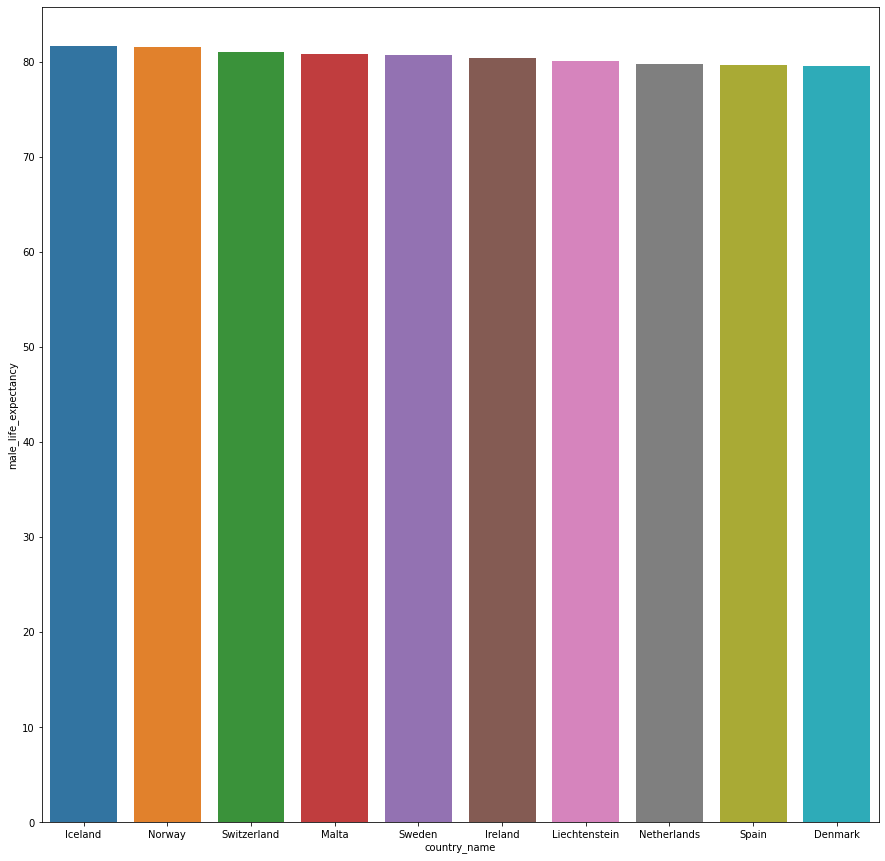

In [18]:
new_index = (data.sort_values(by=['male_life_expectancy'],ascending=False).head(10)).index.values
sorted_data = data.reindex(new_index)

#Visualization

plt.figure(figsize=(15,15))
sns.barplot(x=sorted_data['country_name'],y=sorted_data['male_life_expectancy'])


<AxesSubplot:xlabel='country_name', ylabel='female_life_expectancy'>

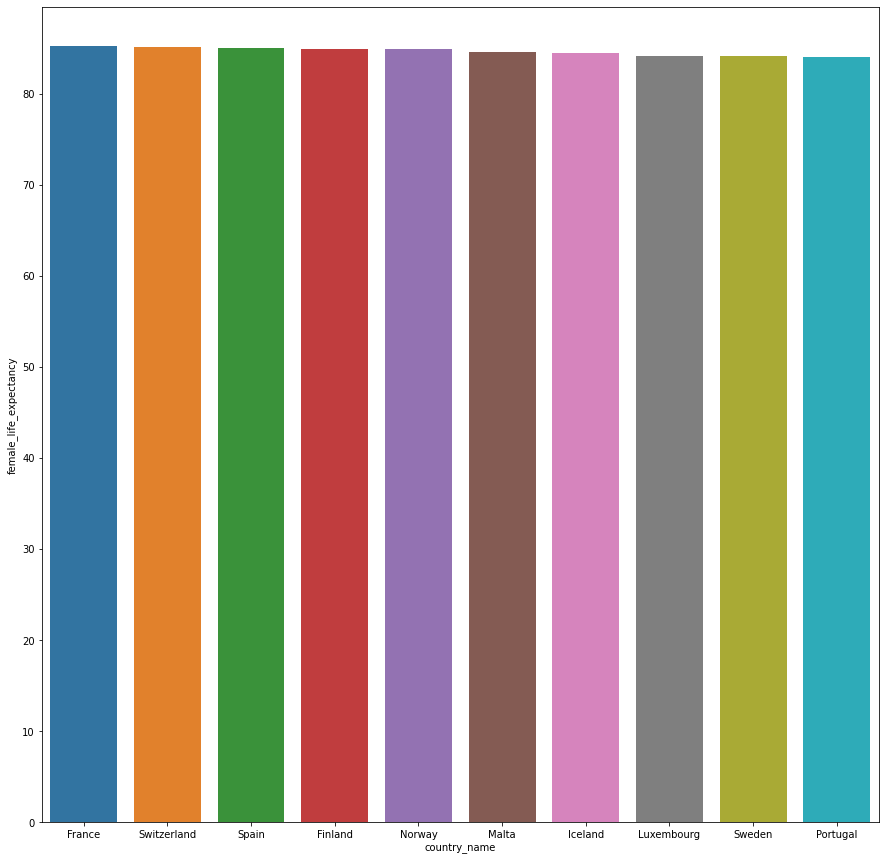

In [19]:
new_index = (data.sort_values(by=['female_life_expectancy'],ascending=False).head(10)).index.values
sorted_data = data.reindex(new_index)

#Visualization

plt.figure(figsize=(15,15))
sns.barplot(x=sorted_data['country_name'],y=sorted_data['female_life_expectancy'])

<AxesSubplot:>

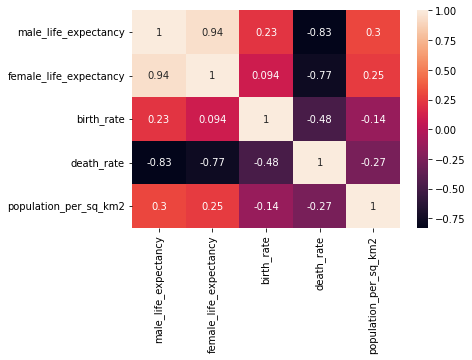

In [20]:
sns.heatmap(data.corr(),annot=True)